# Bab 4: Building Models with Distance Metrics and Nearest Neighbors

Notebook ini merangkum Bab 4 buku *scikit-learn Cookbook* (Third Edition) karya John Sukup. Bab ini membahas model berbasis jarak, terutama k-nearest neighbors (KNN): bagaimana mengukur "kemiripan" antar data, menerapkan KNN, memilih metrik jarak yang tepat, melakukan hyperparameter tuning, dan mengevaluasi performanya.

Semua kode di notebook ini sudah dijalankan, jadi outputnya langsung terlihat begitu file dibuka.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(2024)
pd.set_option("display.precision", 4)

## 1. Pengantar Distance Metrics

Distance metrics adalah komponen fundamental di banyak algoritma ML, terutama yang bergantung pada konsep kemiripan atau ketidakmiripan antar titik data. Tiga metrik yang paling umum:

- **Euclidean distance**: jarak garis lurus (seperti burung terbang) dalam ruang n-dimensi. Ini metrik default yang paling sering dipakai.
- **Manhattan distance**: bayangkan menyusuri kota berbentuk grid seperti Manhattan di New York, kita hanya bisa bergerak horizontal atau vertikal, tidak diagonal. Cocok ketika selisih absolut lebih bermakna atau lebih tahan terhadap outlier dibanding selisih kuadrat.
- **Minkowski distance**: generalisasi dari Euclidean dan Manhattan, di mana parameter p menentukan cara agregasi jaraknya (p=1 untuk Manhattan, p=2 untuk Euclidean).

## 2. Memahami KNN

KNN adalah algoritma supervised learning yang mengklasifikasikan titik data baru berdasarkan label mayoritas dari k tetangga terdekatnya di data training. Kita akan memakai dataset Iris untuk mendemonstrasikan implementasi dasarnya.

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2024
)
print(f"Jumlah data training: {len(X_train)}, data testing: {len(X_test)}")

Jumlah data training: 120, data testing: 30


In [3]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9333333333333333


Hanya dengan pengaturan default, model KNN ini sudah mencapai akurasi yang cukup tinggi pada dataset Iris.

### Cara Kerja KNN

KNN mengklasifikasikan titik data baru berdasarkan label mayoritas dari k tetangga terdekatnya di data training:

- **Memilih k**: parameter k menentukan berapa banyak tetangga terdekat yang dipertimbangkan. Nilai k yang kecil membuat model sensitif terhadap noise, sementara k yang besar bisa menghaluskan prediksi tapi berisiko mengabaikan pola lokal.
- **Menghitung jarak**: KNN memakai metrik jarak (Euclidean, Manhattan, atau Minkowski) untuk menentukan tetangga mana yang paling dekat. Pilihan metrik ini bisa sangat memengaruhi hasil klasifikasi.
- **Mekanisme voting**: untuk klasifikasi, KNN memberi label berdasarkan voting mayoritas dari k tetangga terdekat. Untuk regresi, KNN menghitung rata-rata nilai dari tetangga-tetangga tersebut.

Memilih nilai k yang optimal bisa dilakukan lewat cross-validation (mengevaluasi performa di berbagai nilai k) atau metode elbow (memplot akurasi terhadap nilai k dan mencari titik di mana penambahan k memberi manfaat yang makin kecil).

## 3. Tinjauan Distance Metrics

Pemilihan metrik jarak bisa sangat memengaruhi performa model. Kita akan membuat dua dataset sintetis untuk melihat bagaimana Euclidean, Manhattan, dan Minkowski distance berperforma berbeda tergantung struktur datanya.

In [4]:
from sklearn.datasets import make_circles

n_samples = 300

# Dataset lingkaran dengan noise tinggi
X_circles, y_circles = make_circles(n_samples=n_samples, noise=0.3, factor=0.3, random_state=2024)
X_circles_train, X_circles_test, y_circles_train, y_circles_test = train_test_split(
    X_circles, y_circles, test_size=0.2, random_state=2024
)

# Dataset pola papan catur (checkerboard)
x_grid = np.linspace(0, 4, int(np.sqrt(n_samples)))
y_grid = np.linspace(0, 4, int(np.sqrt(n_samples)))
xx, yy = np.meshgrid(x_grid, y_grid)
X_moons = np.column_stack((xx.ravel(), yy.ravel()))
y_moons = np.mod(np.floor(xx.ravel()) + np.floor(yy.ravel()), 2)
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.2, random_state=2024
)

In [5]:
metrics = ["euclidean", "manhattan", "minkowski"]
results = {"circles": {}, "moons": {}}

for metric in metrics:
    knn_circles = KNeighborsClassifier(n_neighbors=3, metric=metric)
    knn_circles.fit(X_circles_train, y_circles_train)
    y_pred_circles = knn_circles.predict(X_circles_test)
    results["circles"][metric] = accuracy_score(y_circles_test, y_pred_circles)

    knn_moons = KNeighborsClassifier(n_neighbors=3, metric=metric)
    knn_moons.fit(X_moons_train, y_moons_train)
    y_pred_moons = knn_moons.predict(X_moons_test)
    results["moons"][metric] = accuracy_score(y_moons_test, y_pred_moons)

results

{'circles': {'euclidean': 0.7833333333333333,
  'manhattan': 0.7666666666666667,
  'minkowski': 0.7833333333333333},
 'moons': {'euclidean': 0.8103448275862069,
  'manhattan': 0.8448275862068966,
  'minkowski': 0.8103448275862069}}

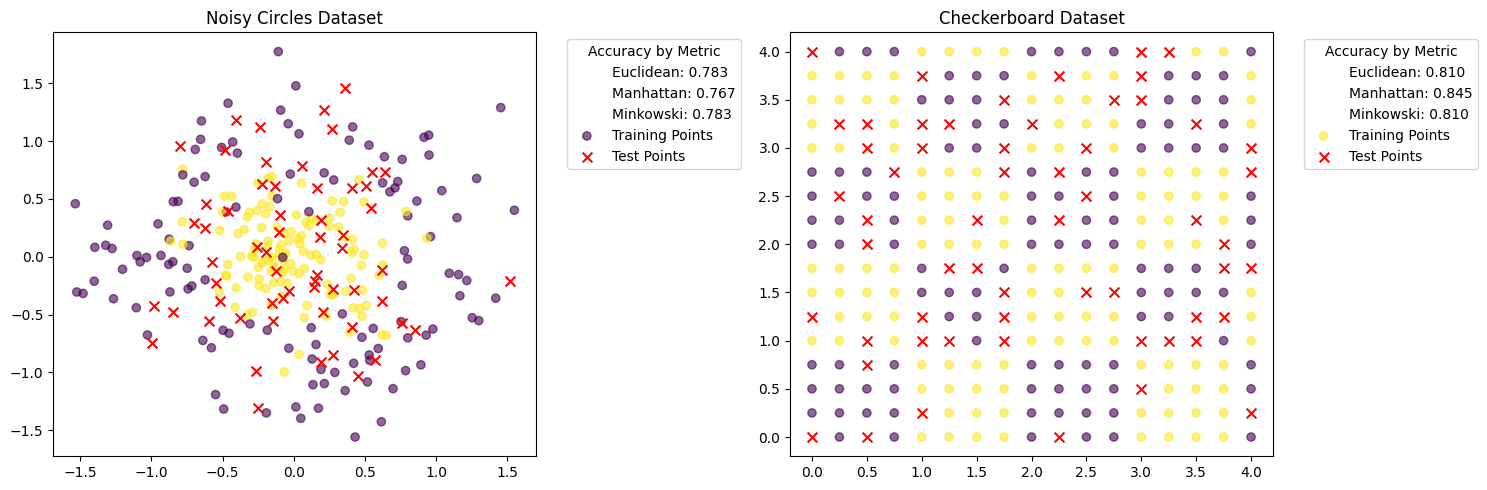

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

scatter1_train = ax1.scatter(
    X_circles_train[:, 0], X_circles_train[:, 1],
    c=y_circles_train, cmap="viridis", alpha=0.6, label="Training Points",
)
scatter1_test = ax1.scatter(
    X_circles_test[:, 0], X_circles_test[:, 1],
    color="red", marker="x", s=50, label="Test Points",
)
ax1.set_title("Noisy Circles Dataset")

lines1 = [plt.Line2D([0], [0], color="white") for _ in metrics]
legend_text1 = [
    f"Euclidean: {results['circles']['euclidean']:.3f}",
    f"Manhattan: {results['circles']['manhattan']:.3f}",
    f"Minkowski: {results['circles']['minkowski']:.3f}",
]
ax1.legend(
    lines1 + [scatter1_train, scatter1_test],
    legend_text1 + ["Training Points", "Test Points"],
    title="Accuracy by Metric", bbox_to_anchor=(1.05, 1), loc="upper left",
)

scatter2_train = ax2.scatter(
    X_moons_train[:, 0], X_moons_train[:, 1],
    c=y_moons_train, cmap="viridis", alpha=0.6, label="Training Points",
)
scatter2_test = ax2.scatter(
    X_moons_test[:, 0], X_moons_test[:, 1],
    color="red", marker="x", s=50, label="Test Points",
)
ax2.set_title("Checkerboard Dataset")

lines2 = [plt.Line2D([0], [0], color="white") for _ in metrics]
legend_text2 = [
    f"Euclidean: {results['moons']['euclidean']:.3f}",
    f"Manhattan: {results['moons']['manhattan']:.3f}",
    f"Minkowski: {results['moons']['minkowski']:.3f}",
]
ax2.legend(
    lines2 + [scatter2_train, scatter2_test],
    legend_text2 + ["Training Points", "Test Points"],
    title="Accuracy by Metric", bbox_to_anchor=(1.05, 1), loc="upper left",
)

plt.tight_layout()
plt.show()

Pada dataset checkerboard, yang data pointnya tersusun rapi dalam pola grid, Manhattan distance memang diharapkan berperforma baik karena jarak antar titik pada grid lebih natural diukur secara horizontal-vertikal ketimbang garis lurus diagonal.

Distance metrics punya kegunaan masing-masing dan sebaiknya dipilih sesuai situasi, bukan asal pakai yang sama untuk semua kasus:

- **Euclidean distance**: metrik paling umum dipakai di KNN. Sensitif terhadap outlier dan bekerja paling baik kalau fitur-fiturnya sudah di-scale secara serupa.
- **Manhattan distance**: juga dikenal sebagai L1 distance atau city block distance. Mengukur jumlah selisih absolut antar koordinat, lebih tahan terhadap outlier dibanding Euclidean.
- **Minkowski distance**: generalisasi dari keduanya, dengan parameter p yang fleksibel disesuaikan karakteristik dataset.

Pemilihan metrik juga perlu memperhatikan sensitivitas terhadap skala fitur (standardisasi tetap penting sebelum menerapkan KNN) dan efek dimensi tinggi, di mana jarak antar titik bisa jadi kurang bermakna seiring bertambahnya jumlah fitur (curse of dimensionality).

## 4. Hyperparameter Tuning pada KNN

Hyperparameter adalah pengaturan yang menentukan "cara belajar" model, berbeda dengan parameter yang dipelajari langsung dari data saat training. Kita akan memakai `GridSearchCV()` untuk mencari kombinasi terbaik dari jumlah tetangga, skema pembobotan, dan metrik jarak pada dataset Iris.

In [7]:
from sklearn.model_selection import GridSearchCV

knn = KNeighborsClassifier()

param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"],
}

grid_search = GridSearchCV(knn, param_grid, cv=5, scoring="accuracy")
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)

Best parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best cross-validation score: 0.9916666666666668


`GridSearchCV()` menguji seluruh kombinasi hyperparameter yang kita tentukan secara menyeluruh (exhaustive search), dipadukan dengan cross-validation untuk memastikan hasil yang dipilih benar-benar robust, bukan sekadar kebetulan cocok dengan satu pembagian data tertentu.

Sebagai alternatif ketika ruang hyperparameter sangat besar, `RandomizedSearchCV()` bisa dipakai, yang mengambil sampel acak dari kombinasi parameter alih-alih mencoba semuanya, menghemat waktu komputasi dengan hasil yang biasanya tetap cukup baik.

## 5. Evaluasi Performa KNN

Setelah mendapat hyperparameter terbaik, saatnya mengevaluasi model secara lebih menyeluruh: cross-validation score, learning curve, confusion matrix, dan classification report.

In [8]:
from sklearn.model_selection import learning_curve, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

cv_scores = cross_val_score(grid_search.best_estimator_, X_train, y_train, cv=5)
print("Cross-validation scores:", cv_scores)
print("Mean CV score:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

Cross-validation scores: [0.95833333 1.         1.         1.         1.        ]
Mean CV score: 0.9916666666666668
Standard deviation: 0.016666666666666653


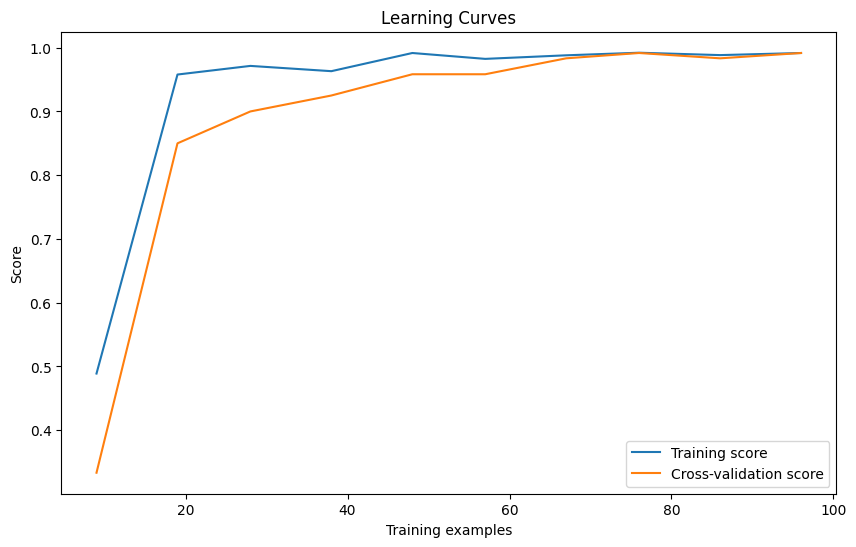

In [9]:
train_sizes, train_scores, test_scores = learning_curve(
    grid_search.best_estimator_, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10), cv=5,
)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, np.mean(train_scores, axis=1), label="Training score")
plt.plot(train_sizes, np.mean(test_scores, axis=1), label="Cross-validation score")
plt.xlabel("Training examples")
plt.ylabel("Score")
plt.legend(loc="best")
plt.title("Learning Curves")
plt.show()

Learning curve menunjukkan bagaimana performa model berubah seiring bertambahnya jumlah data training, memberi gambaran apakah model mengalami underfitting, overfitting, atau justru sudah mencapai titik di mana penambahan data training tidak lagi memberi manfaat signifikan.

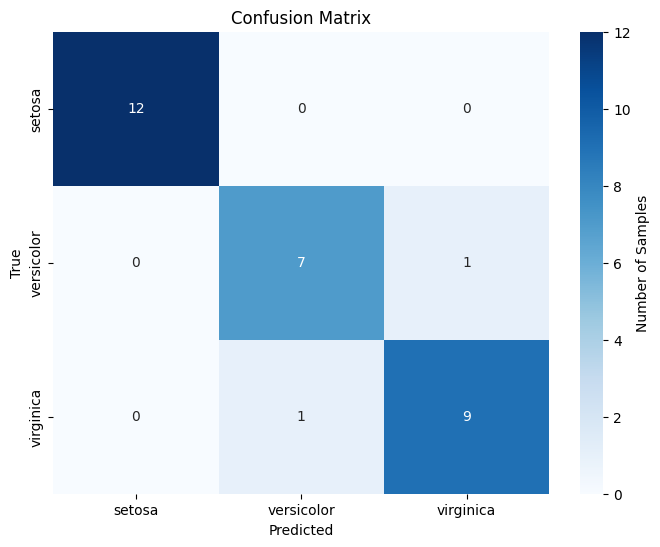

In [10]:
y_pred = grid_search.best_estimator_.predict(X_test)
class_names = iris.target_names

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names,
    cbar_kws={"label": "Number of Samples"},
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

Dari confusion matrix ini, kita bisa melihat seberapa banyak prediksi yang benar (sepanjang diagonal) dibanding yang salah untuk tiap kelas bunga Iris.

In [11]:
report_dict = classification_report(
    y_test, y_pred, target_names=class_names, output_dict=True
)
report_df = pd.DataFrame(report_dict).transpose()

styled_df = report_df.style.background_gradient(
    cmap="Blues", subset=["precision", "recall", "f1-score"]
).format({
    "precision": "{:.3f}",
    "recall": "{:.3f}",
    "f1-score": "{:.3f}",
    "support": "{:.0f}",
})
styled_df

,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,12
versicolor,0.875,0.875,0.875,8
virginica,0.900,0.900,0.900,10
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.925,0.925,30
weighted avg,0.933,0.933,0.933,30


Classification report merangkum beberapa metrik penting sekaligus:

- **Precision**: akurasi dari prediksi positif, dihitung sebagai TP / (TP + FP).
- **Recall (sensitivity)**: kemampuan model mengenali seluruh instance yang relevan, dihitung sebagai TP / (TP + FN).
- **F1-score**: rata-rata harmonik dari precision dan recall, berguna terutama untuk dataset yang tidak seimbang.
- **Accuracy**: rasio total prediksi benar dari keseluruhan prediksi, dihitung sebagai (TP + TN) / (TP + TN + FP + FN).
- **Macro avg**: rata-rata metrik di semua label secara setara.
- **Weighted avg**: rata-rata metrik di semua label, dibobotkan berdasarkan jumlah sampel tiap label.

Dataset Iris memang tergolong mudah untuk model klasifikasi sederhana, jadi skor presisi, recall, dan F1 yang sangat tinggi (bahkan sempurna untuk kelas tertentu) di sini wajar terjadi. Di dunia nyata, skor sebagus ini jarang muncul begitu saja tanpa pemahaman mendalam soal konteks masalah yang sedang dimodelkan.

Satu hal penting yang perlu diperhatikan: ketika dataset punya distribusi kelas yang tidak seimbang, akurasi saja bisa menyesatkan. Dalam kasus ini, metrik seperti precision-recall curve atau ROC-AUC lebih disarankan, dan teknik resampling (oversampling kelas minoritas atau undersampling kelas mayoritas) bisa membantu menyeimbangkan data sebelum training.

## 6. Latihan Praktis: Membangun dan Mengevaluasi KNN

Sebagai latihan penutup, mari terapkan keseluruhan alur kerja KNN, mulai dari preprocessing hingga evaluasi, pada dataset Wine yang punya lebih banyak fitur dan kelas dibanding Iris.

In [12]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

wine = load_wine()
X_wine, y_wine = wine.data, wine.target

X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine, y_wine, test_size=0.2, random_state=2024, stratify=y_wine
)

# Preprocessing: scaling, karena KNN sensitif terhadap skala fitur
scaler = StandardScaler()
X_train_w_scaled = scaler.fit_transform(X_train_w)
X_test_w_scaled = scaler.transform(X_test_w)

# Grid search untuk mencari hyperparameter terbaik
param_grid_wine = {
    "n_neighbors": list(range(1, 21)),
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"],
}
grid_search_wine = GridSearchCV(
    KNeighborsClassifier(), param_grid_wine, cv=5, scoring="accuracy"
)
grid_search_wine.fit(X_train_w_scaled, y_train_w)

print("Best parameters:", grid_search_wine.best_params_)
print("Best cross-validation score:", grid_search_wine.best_score_)

Best parameters: {'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'uniform'}
Best cross-validation score: 0.9788177339901478


In [13]:
# Evaluasi model terbaik pada data testing
y_pred_wine = grid_search_wine.best_estimator_.predict(X_test_w_scaled)
print("Test accuracy:", accuracy_score(y_test_w, y_pred_wine))
print()
print(classification_report(y_test_w, y_pred_wine, target_names=wine.target_names))

Test accuracy: 0.9722222222222222

              precision    recall  f1-score   support

     class_0       0.92      1.00      0.96        12
     class_1       1.00      0.93      0.96        14
     class_2       1.00      1.00      1.00        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



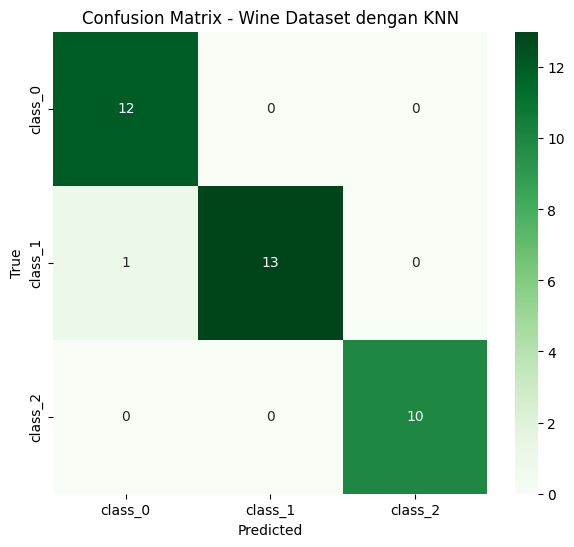

In [14]:
cm_wine = confusion_matrix(y_test_w, y_pred_wine)
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_wine, annot=True, fmt="d", cmap="Greens",
    xticklabels=wine.target_names, yticklabels=wine.target_names,
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - Wine Dataset dengan KNN")
plt.show()

Latihan ini merangkum keseluruhan alur bab: scaling fitur (karena KNN sensitif terhadap skala), pencarian hyperparameter terbaik lewat grid search dengan cross-validation, lalu evaluasi akhir di data testing memakai classification report dan confusion matrix.

## Poin-poin Penting Bab 4

- Distance metrics (Euclidean, Manhattan, Minkowski) adalah fondasi algoritma berbasis jarak seperti KNN, dan pilihan metrik yang tepat bergantung pada struktur dan karakteristik dataset.
- KNN mengklasifikasikan data baru berdasarkan voting mayoritas dari k tetangga terdekat, dengan nilai k yang sangat memengaruhi trade-off antara sensitivitas terhadap noise dan kemampuan menangkap pola lokal.
- Scaling fitur sangat penting sebelum menerapkan KNN, karena metrik jarak seperti Euclidean sangat sensitif terhadap perbedaan skala antar fitur.
- `GridSearchCV()` dan `RandomizedSearchCV()` membantu mencari kombinasi hyperparameter terbaik secara sistematis, dipadukan dengan cross-validation untuk hasil yang lebih bisa diandalkan.
- Evaluasi model KNN sebaiknya tidak berhenti di accuracy saja: learning curve, confusion matrix, dan classification report (precision, recall, F1-score) memberi gambaran yang jauh lebih lengkap soal performa model.
- Untuk dataset yang tidak seimbang, accuracy bisa menyesatkan, metrik seperti precision-recall curve atau ROC-AUC, dipadukan dengan teknik resampling, jadi pertimbangan penting.

Referensi: Sukup, J. (2025). *scikit-learn Cookbook*, Third Edition, Bab 4 "Building Models with Distance Metrics and Nearest Neighbors". Packt Publishing.